<a href="https://colab.research.google.com/github/Cap-Abhinay/house-price-prediction/blob/main/house_price_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# California House Price Prediction

## 1. Problem statement
Predict the **median house value** of California districts from features such as median income, house age, and location.

**Success metrics:** RMSE and R² on a held-out test set.

**Approach:** EDA → preprocessing → baseline linear regression → regularized models and feature engineering → error analysis.

> Note: the target `MedHouseVal` is in units of $100,000.

## 2. Setup and load data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import fetch_california_housing

sns.set_theme(style="whitegrid")

data = fetch_california_housing(as_frame=True)
df = data.frame
df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [2]:
# Inspect the data
print(df.shape)
df.info()

(20640, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


In [3]:
df.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


In [4]:
df.isnull().sum()

,0
MedInc,0
HouseAge,0
AveRooms,0
AveBedrms,0
Population,0
AveOccup,0
Latitude,0
Longitude,0
MedHouseVal,0


**Column meanings:**
- `MedInc`: median income in the district (units of $10,000)
- `HouseAge`: median house age
- `AveRooms`: Average number of rooms
- `AveBedrms`: Average number of bedrooms per houshold.
- `Population`: Total district population.
- `AveOccup`: Average person per household.
- `Latitude`, `Longitude`: Coordinates.
- `MedHouseVal` (target): Median value.

**What I noticed from `describe()`:**
1. There is no missing value.
2. AveRooms, AveBedrms, AveOccup, and Population have extreme outliers (max far above the 75%).
3. The target is capped at 5.0 ($500k).
4. Features have very different scales, so scaling is needed.

## 3. Exploratory Data Analysis

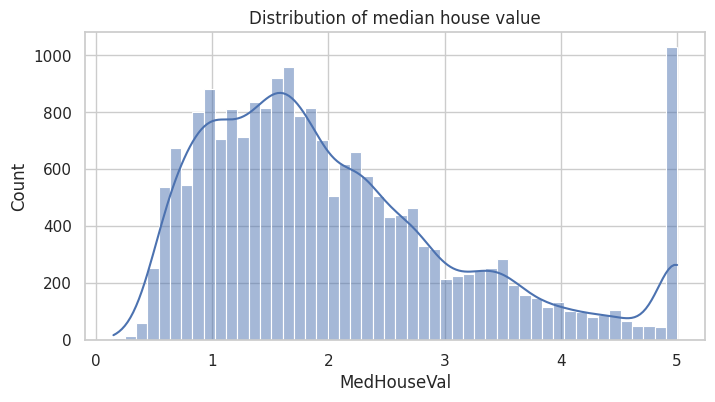

In [5]:
plt.figure(figsize=(8, 4))
sns.histplot(df["MedHouseVal"], bins=50, kde=True)
plt.title("Distribution of median house value")
plt.show()

**Observation:**

-> Max households value range from 0.5 to 2.5

-> At right of histogram we can see 5 ($500,000) is capped value.

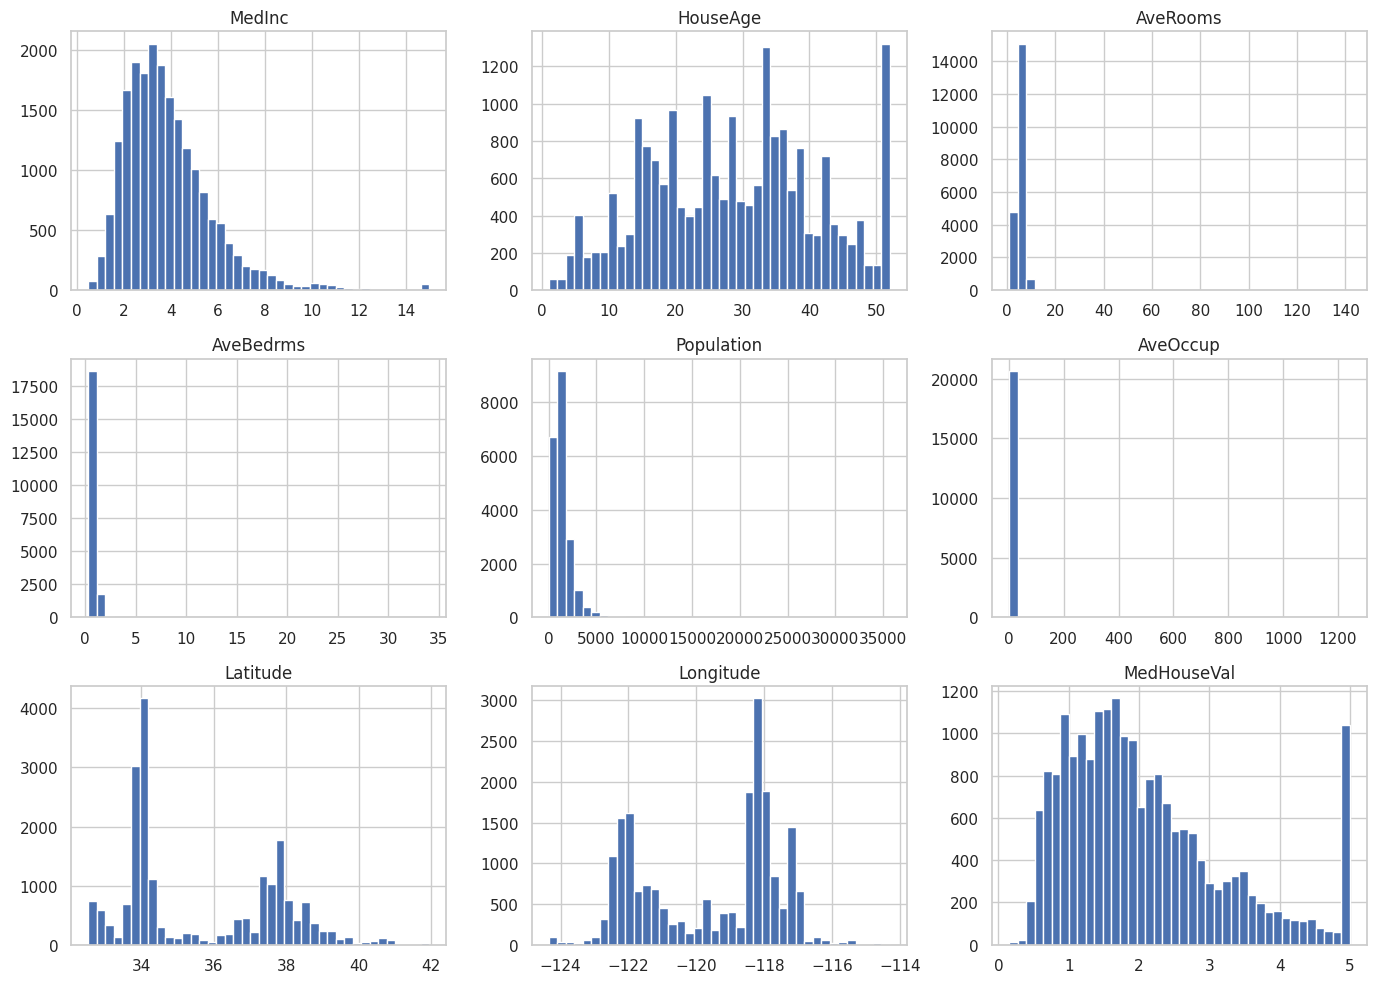

In [6]:
# Histograms of all features
df.hist(bins=40, figsize=(14, 10))
plt.tight_layout()
plt.show()

**Observation:**

-> Right Skewed - MedInc,MedHouseVal and Population.

-> AveRooms, AveBedrms and AveOccup contain extreme outliers: almost all values sit in a narrow range, but a few reach far higher values (e.g., AveOccup above 1,000).

-> MedInc (at 15), HouseAge (at 52) and MedHouseVal (at 5) show spikes at their maximum values, indicating the data is capped.

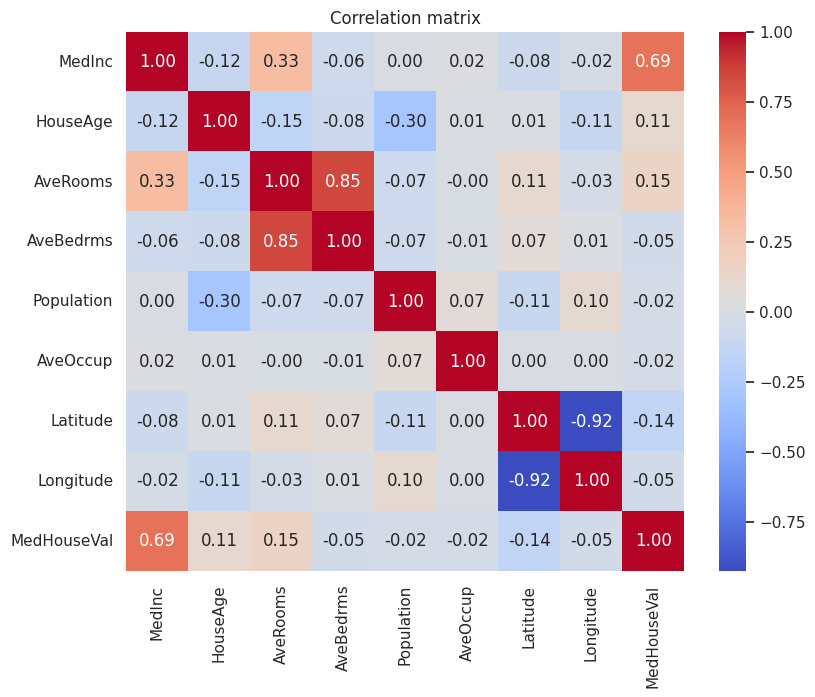

In [7]:
# Correlation heatmap
plt.figure(figsize=(9, 7))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation matrix")
plt.show()

**Observation:**
- MedInc: Strongest positive correlation with house value (0.69).
- AveRooms & AveBedrms: Strong positive correlation (0.85).
- Median income is the most strongly correlated feature with median house value
- Latitude and Longitude are strongly negatively correlated with each other (about -0.92), which makes sense because California runs diagonally.

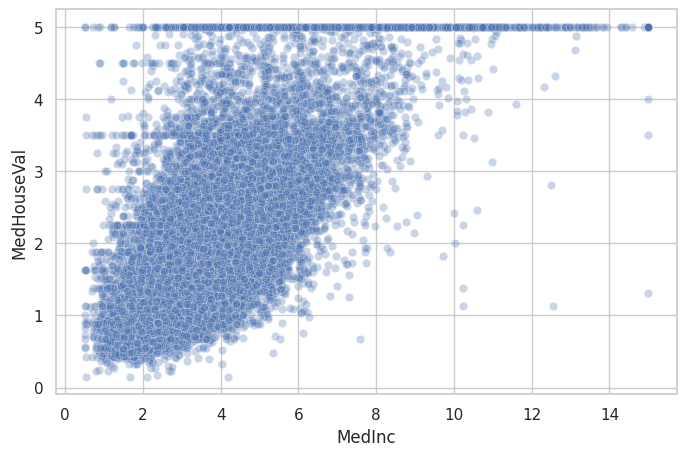

In [8]:
# Income vs price
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="MedInc", y="MedHouseVal", alpha=0.3)
plt.show()

**Observation:**
- Positive relationship: As median income (MedInc) increases, median house value (MedHouseVal) generally increases.
- A horizontal line at approximately 5.0 indicates that some house values are capped at the dataset's upper limit

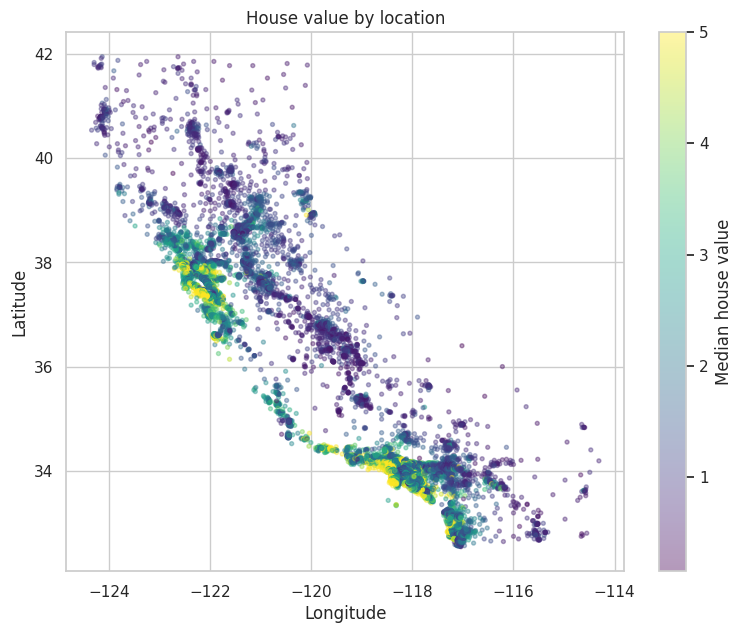

In [9]:
# Geographic pattern
plt.figure(figsize=(9, 7))
sc = plt.scatter(df["Longitude"], df["Latitude"], c=df["MedHouseVal"],
                 cmap="viridis", alpha=0.4, s=8)
plt.colorbar(sc, label="Median house value")
plt.xlabel("Longitude"); plt.ylabel("Latitude")
plt.title("House value by location")
plt.show()

**Observation:**
- House prices appear spatially clustered rather than uniformly distributed.

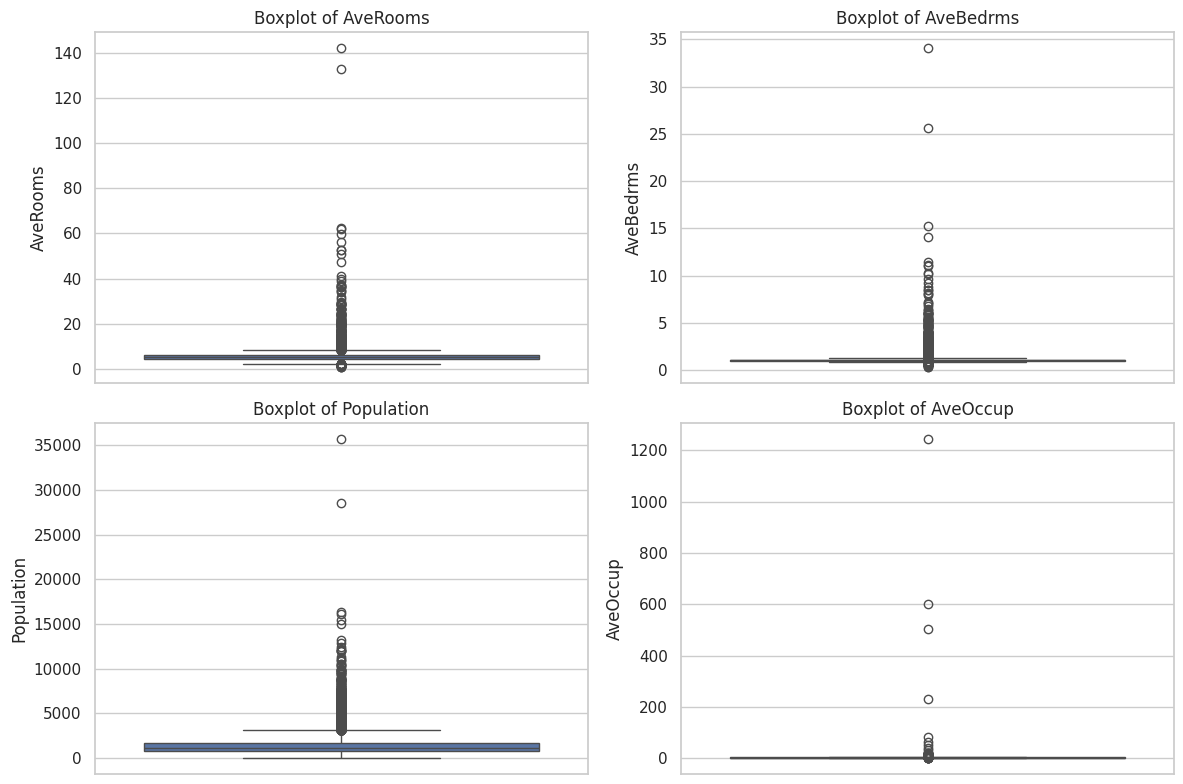

In [10]:
plt.figure(figsize=(12, 8))

cols = ["AveRooms", "AveBedrms", "Population", "AveOccup"]

for i, col in enumerate(cols, 1):
    plt.subplot(2, 2, i)
    sns.boxplot(y=df[col])
    plt.title(f"Boxplot of {col}")

plt.tight_layout()
plt.show()

In [11]:
total = len(df)

print("AveRooms > 20:", (df["AveRooms"] > 20).sum())
print("AveBedrms > 5:", (df["AveBedrms"] > 5).sum())
print("AveOccup > 10:", (df["AveOccup"] > 10).sum())
print("Population > 10000:", (df["Population"] > 10000).sum())
print("Total rows:", total)

AveRooms > 20: 69
AveBedrms > 5: 45
AveOccup > 10: 37
Population > 10000: 23
Total rows: 20640


In [12]:
Q1 = df["AveOccup"].quantile(0.25)
Q3 = df["AveOccup"].quantile(0.75)
IQR = Q3 - Q1
upper = Q3 + 1.5 * IQR
print(upper, (df["AveOccup"] > upper).sum())

4.5610405893536905 704


**Outlier decision:**
- For all boxlplots there are outliers so we can delete the extreme unreasonable ones.



## 4. Preprocessing
Split **first**, then scale, so no test information leaks into training.

In [13]:
mask = (
    (df["AveRooms"] > 20) |
    (df["AveBedrms"] > 5) |
    (df["AveOccup"] > 10) |
    (df["Population"] > 10000)
)
print("Rows to remove:", mask.sum(), f"({mask.mean()*100:.2f}%)")

df_clean = df[~mask].copy()
print(df.shape, "->", df_clean.shape)

Rows to remove: 131 (0.63%)
(20640, 9) -> (20509, 9)


In [14]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = df_clean.drop("MedHouseVal", axis=1)
y = df_clean["MedHouseVal"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)   # fit on train only
X_test_scaled = scaler.transform(X_test)         # transform test only

print("Train:", X_train.shape, "Test:", X_test.shape)

Train: (16407, 8) Test: (4102, 8)


## 5. Baseline: Linear Regression

In [15]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

def evaluate(name, model, Xtr, Xte):
    model.fit(Xtr, y_train)
    pred = model.predict(Xte)
    rmse = np.sqrt(mean_squared_error(y_test, pred))
    r2 = r2_score(y_test, pred)
    print(f"{name}: RMSE={rmse:.4f}, R2={r2:.4f}")
    return {"Model": name, "RMSE": rmse, "R2": r2}

results = []
results.append(evaluate("Linear Regression", LinearRegression(), X_train_scaled, X_test_scaled))

Linear Regression: RMSE=0.6798, R2=0.6539


**Baseline interpretation:**
- RMSE = 0.6798 means predictions are off by about $68,000 on average (target is in units of $100,000). R² = 0.6539 means the model explains about 65% of the variance in house values.

## 6. Improvements

In [21]:
from sklearn.linear_model import RidgeCV, LassoCV
alphas = np.logspace(-3, 3, 50)
results.append(evaluate("Ridge", RidgeCV(alphas=alphas, cv=5), X_train_scaled, X_test_scaled))
results.append(evaluate("Lasso", LassoCV(alphas=alphas, cv=5, random_state=42), X_train_scaled, X_test_scaled))

Ridge: RMSE=0.6798, R2=0.6539
Lasso: RMSE=0.6798, R2=0.6540


In [31]:
df_fe = df_clean.copy()
df_fe["RoomsPerPerson"] = df_fe["AveRooms"] / df_fe["AveOccup"]
df_fe["BedroomRatio"] = df_fe["AveBedrms"] / df_fe["AveRooms"]

X_fe = df_fe.drop("MedHouseVal", axis=1)
Xtr_fe, Xte_fe, _, _ = train_test_split(X_fe, y, test_size=0.2, random_state=42)

scaler_fe = StandardScaler()
Xtr_fe_s = scaler_fe.fit_transform(Xtr_fe)
Xte_fe_s = scaler_fe.transform(Xte_fe)

results.append(evaluate("Linear Reg + new features", LinearRegression(), Xtr_fe_s, Xte_fe_s))

Linear Reg + new features: RMSE=0.6597, R2=0.6741


In [32]:
from sklearn.decomposition import PCA

pca = PCA(n_components=0.95)
Xtr_pca = pca.fit_transform(X_train_scaled)
Xte_pca = pca.transform(X_test_scaled)
print("Components kept:", pca.n_components_)

results.append(evaluate("Linear Reg + PCA", LinearRegression(), Xtr_pca, Xte_pca))

Components kept: 6
Linear Reg + PCA: RMSE=0.8006, R2=0.5200


In [28]:
# Results table
pd.DataFrame(results)

,Model,RMSE,R2
0,Linear Regression,0.679813,0.653933
1,Ridge,0.679807,0.653938
2,Lasso,0.679772,0.653974
3,Linear Reg + new features,0.659730,0.674077
4,Linear Reg + PCA,0.800631,0.519993
5,Linear Reg + PCA,0.800631,0.519993
6,Linear Reg + PCA,0.800631,0.519993


## 7. Error analysis

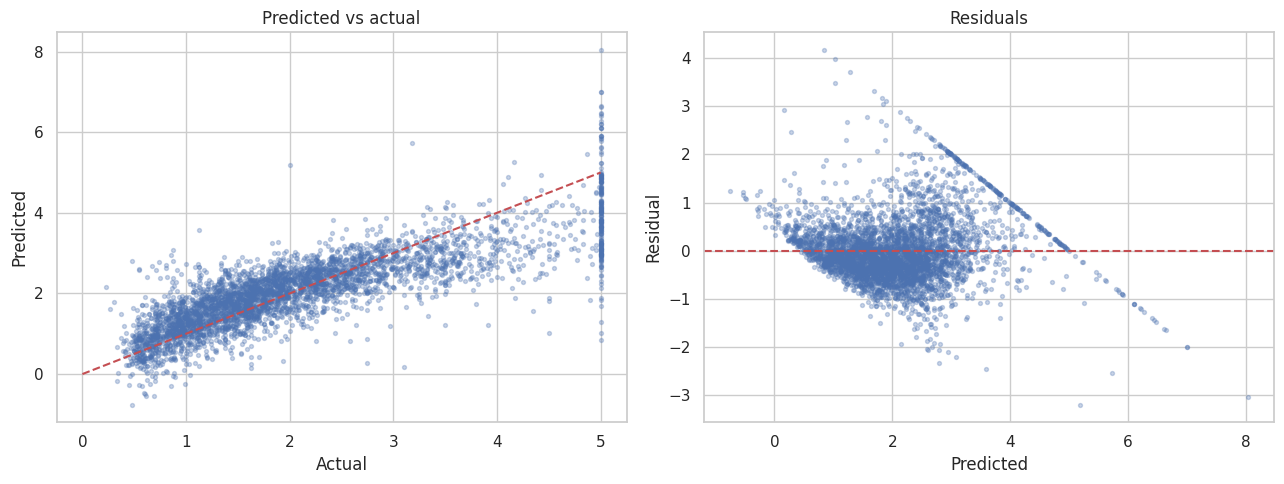

RMSE on capped (5.0) rows: 1.5261261049630677
RMSE on other rows:       0.5815284249421974


In [29]:
best = LinearRegression().fit(Xtr_fe_s, y_train)   # use whichever model scored best
pred = best.predict(Xte_fe_s)
resid = y_test - pred

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].scatter(y_test, pred, alpha=0.3, s=8)
ax[0].plot([0, 5], [0, 5], "r--")
ax[0].set_xlabel("Actual"); ax[0].set_ylabel("Predicted"); ax[0].set_title("Predicted vs actual")

ax[1].scatter(pred, resid, alpha=0.3, s=8)
ax[1].axhline(0, color="r", ls="--")
ax[1].set_xlabel("Predicted"); ax[1].set_ylabel("Residual"); ax[1].set_title("Residuals")
plt.tight_layout(); plt.show()

# Where is the model worst?
capped = y_test >= 5
print("RMSE on capped (5.0) rows:", np.sqrt(np.mean(resid[capped] ** 2)))
print("RMSE on other rows:      ", np.sqrt(np.mean(resid[~capped] ** 2)))

**Observations**  
- Predicted vs actual: a flat horizontal band of points at actual = 5.0 means the model can’t predict the capped districts.
- Residuals: a funnel shape (errors growing with price) or a curve means the relationship isn’t purely linear.

## 8. Conclusion
- **What worked:** Removing extreme outliers and adding the engineered features (RoomsPerPerson, BedroomRatio), which lowered RMSE from 0.6798 to 0.6597 (R² 0.654 → 0.674).
- **What didn't:** Ridge and Lasso gave identical results to the baseline since the model was not overfitting, and PCA made the results worse (RMSE 0.8006) by discarding useful information.
- **Key insights:** MedInc and location drive prices, the target cap at 5.0 limits linear models, and linear models can't capture location effects.
- **Next steps:** Random Forest / XGBoost, log-transforming the target, and better location features (e.g., distance to the coast or to LA and San Francisco).